# One season against the others

How did the last fire season compare with the years before? The same open
archives (no key), month by month, and `anomaly()` for the whole season:
its rank among the years and a robust z-score against the median.

The comparison is between fires FIRMS saw. A season with more clouds, or a
month when a satellite had no data (`missing_days()`), looks calmer than it
was: not measured is not zero.

In [1]:
from collections import defaultdict
from datetime import date
from statistics import median

import httpx
import matplotlib.pyplot as plt

from firms_client import ATTRIBUTION, VIIRS_SNPP, anomaly, fetch_archive, select
from firms_client.sources import archive_years

COUNTRY = "Italy"
monthly = {}
async with httpx.AsyncClient(timeout=300) as client:
    for year in archive_years(VIIRS_SNPP, until=date.today().year - 1):
        rows = await fetch_archive(client, VIIRS_SNPP, year, COUNTRY)
        if rows is None:
            continue
        days = defaultdict(set)
        for h in select(rows):
            days[h.acq_date.month].add((round(h.latitude, 2), round(h.longitude, 2), h.acq_date))
        monthly[year] = [len(days[m]) for m in range(1, 13)]
LAST = max(monthly)
print(f"years {min(monthly)}-{LAST}; the season compared: {LAST}")

years 2012-2025; the season compared: 2025


## Month by month

Fire-days per month (1 km cells), the last year against the median and the
range of the others.

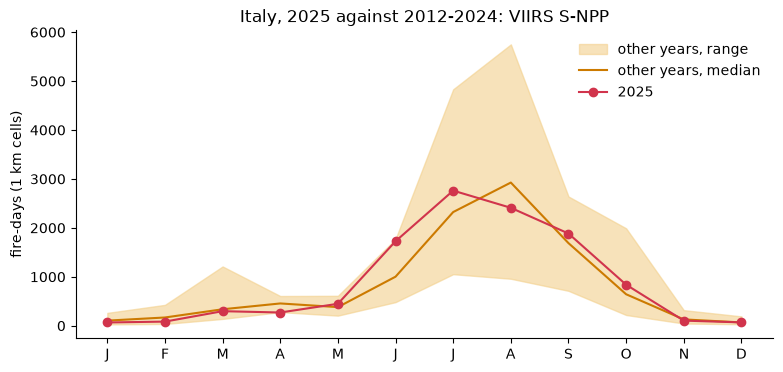

In [2]:
others = [v for y, v in monthly.items() if y != LAST]
months = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
mid = [median(v[m] for v in others) for m in range(12)]
low = [min(v[m] for v in others) for m in range(12)]
high = [max(v[m] for v in others) for m in range(12)]

fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(range(12), low, high, color="#f3d08c", alpha=0.6, label="other years, range")
ax.plot(range(12), mid, color="#cc7a00", label="other years, median")
ax.plot(range(12), monthly[LAST], color="#d1344c", marker="o", label=str(LAST))
ax.set_xticks(range(12), months)
ax.set_ylabel("fire-days (1 km cells)")
ax.set_title(f"Italy, {LAST} against {min(monthly)}-{LAST - 1}: VIIRS S-NPP")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## The summer, ranked

June to September, every year against all the others.

In [3]:
summer = {y: sum(v[5:9]) for y, v in monthly.items()}
for year in sorted(summer):
    print(anomaly(summer, year).describe())

2012: 13,062, 2nd highest of 14 years (robust z +4.1)
2013: 7,352, 9th highest of 14 years (robust z -0.6)
2014: 7,330, 11th highest of 14 years (robust z -0.6)
2015: 7,345, 10th highest of 14 years (robust z -0.6)
2016: 8,394, 6th highest of 14 years (robust z +0.4)
2017: 13,990, the highest of 14 years (robust z +4.8)
2018: 5,131, 13th highest of 14 years (robust z -2.9)
2019: 7,996, 7th highest of 14 years (robust z +0.2)
2020: 7,627, 8th highest of 14 years (robust z -0.3)
2021: 11,421, 3rd highest of 14 years (robust z +2.9)
2022: 6,152, 12th highest of 14 years (robust z -1.9)
2023: 8,515, 5th highest of 14 years (robust z +0.5)
2024: 4,839, the lowest of 14 years (robust z -3.2)
2025: 8,781, 4th highest of 14 years (robust z +0.9)


In [4]:
print(ATTRIBUTION)

We acknowledge the use of data and imagery from LANCE FIRMS operated by NASA's Earth Science Data and Information System (ESDIS) with funding provided by NASA Headquarters.
